# LLMs Get Lost In Multi-Turn Conversation (Multi-Turn Lost)

**Paper:** [LLMs Get Lost In Multi-Turn Conversation](https://arxiv.org/abs/2505.06120)

This notebook demonstrates the **Lost in Conversation** phenomenon: when a task is split across multiple
conversation turns (sharded), model performance degrades significantly compared to receiving the full
instruction in a single turn. We implement the paper's **sharding simulation framework** (Section 3),
train a small transformer on a synthetic attribute-combination task, and measure the **aptitude** vs
**reliability** decomposition (Section 6.2) that the paper identifies as the core finding.

**Key findings reproduced:**
1. Multi-turn (sharded) performance is lower than single-turn (full) performance
2. The degradation is primarily an **unreliability** increase, not just an aptitude loss
3. Even 2-shard conversations cause models to get lost (gradual sharding, Section 6.3)

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time
import math
import re

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

import platform
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
Python: 3.11.16
PyTorch: 2.14.1


## 2. Data: Synthetic Attribute-Combination Task & Sharding

The paper shards instructions from benchmarks like GSM8K (math), HumanEval (code), and Spider (SQL).
We create a simplified version: a **synthetic attribute-combination task** where each instruction
specifies three attributes (color, shape, size) and the model must predict all three.

Example:
- **Full:** "Create the code. Color is red. Shape is circle. Size is large."
- **Answer:** (red, circle, large) — three classification targets
- **Shard 1:** "Create the code."
- **Shard 2:** "Color is red."
- **Shard 3:** "Shape is circle."
- **Shard 4:** "Size is large."

We use 5 colors, 5 shapes, and 3 sizes = 75 unique problems, split into 50 train / 25 eval.

**Sharding simulation:** In the sharded setting, the model receives one shard per turn and predicts
the answer at each turn. The model's previous (wrong) predictions from early turns are fed back as
context for later turns — this is the "getting lost" mechanism. A wrong early prediction (e.g.,
guessing "blue" when the color is "red") biases the model toward repeating that error.

In [2]:
COLORS = ['red', 'blue', 'green', 'yellow', 'purple']
SHAPES = ['circle', 'square', 'triangle', 'star', 'hexagon']
SIZES = ['small', 'medium', 'large']

COLOR_TO_ID = {c: i for i, c in enumerate(COLORS)}
SHAPE_TO_ID = {s: i for i, s in enumerate(SHAPES)}
SIZE_TO_ID = {s: i for i, s in enumerate(SIZES)}
SHAPE_TO_ID = {s: i for i, s in enumerate(SHAPES)}

def make_problem(color, shape, size, idx=0):
    full = f"Create the code. Color is {color}. Shape is {shape}. Size is {size}."
    shards = [
        "Create the code.",
        f"Color is {color}.",
        f"Shape is {shape}.",
        f"Size is {size}.",
    ]
    return {
        'id': idx,
        'color': color, 'shape': shape, 'size': size,
        'answer': f'{color}_{shape}_{size}',
        'color_id': COLOR_TO_ID[color],
        'shape_id': SHAPE_TO_ID[shape],
        'size_id': SIZE_TO_ID[size],
        'full': full,
        'shards': shards,
        'n_shards': len(shards),
    }

ALL_UNIQUE = []
idx = 0
for c in COLORS:
    for s in SHAPES:
        for sz in SIZES:
            ALL_UNIQUE.append(make_problem(c, s, sz, idx))
            idx += 1

TRAIN_PROBLEMS = ALL_UNIQUE[:50]
EVAL_PROBLEMS = ALL_UNIQUE[50:]

rng = random.Random(SEED)
TRAIN_AUG = [rng.choice(TRAIN_PROBLEMS) for _ in range(500)]

print(f"Unique problems: {len(ALL_UNIQUE)}")
print(f"Train (unique): {len(TRAIN_PROBLEMS)}, Eval: {len(EVAL_PROBLEMS)}")
print(f"Train (augmented): {len(TRAIN_AUG)}")
p = EVAL_PROBLEMS[0]
print(f"\nExample: {p['full']}")
print(f"  Answer: {p['color']}_{p['shape']}_{p['size']}")
print(f"  Shards: {p['shards']}")

Unique problems: 75
Train (unique): 50, Eval: 25
Train (augmented): 500

Example: Create the code. Color is yellow. Shape is square. Size is large.
  Answer: yellow_square_large
  Shards: ['Create the code.', 'Color is yellow.', 'Shape is square.', 'Size is large.']


## 3. Vocabulary & Tokenization

We use a word-level vocabulary for the instruction text. The model has three classification heads
(color, shape, size) rather than generating text — this makes the task learnable for a small model.

In [3]:
VOCAB_TOKENS = ['<PAD>', '<BOS>', '<EOS>', '<UNK>']

all_words = set()
for p in ALL_UNIQUE:
    all_words.update(p['full'].lower().replace('.', ' . ').split())
    for s in p['shards']:
        all_words.update(s.lower().replace('.', ' . ').split())

VOCAB_TOKENS.extend(sorted(all_words))
VOCAB_SIZE = len(VOCAB_TOKENS)
TOKEN_TO_ID = {t: i for i, t in enumerate(VOCAB_TOKENS)}
ID_TO_TOKEN = {i: t for i, t in enumerate(VOCAB_TOKENS)}

PAD_ID = TOKEN_TO_ID['<PAD>']
BOS_ID = TOKEN_TO_ID['<BOS>']
EOS_ID = TOKEN_TO_ID['<EOS>']

print(f"Vocab size: {VOCAB_SIZE}")

def tokenize(text):
    tokens = text.lower().replace('.', ' . ').split()
    return [TOKEN_TO_ID.get(t, TOKEN_TO_ID['<UNK>']) for t in tokens]

def detokenize(ids):
    return ' '.join(ID_TO_TOKEN.get(i, '<UNK>') for i in ids)

# Test
sample = ALL_UNIQUE[0]
toks = tokenize(sample['full'])
print(f"Tokenized: {toks[:10]}...")
print(f"Detokenized: {detokenize(toks[:10])}...")

Vocab size: 25
Tokenized: [9, 22, 7, 4, 8, 12, 16, 4, 17, 12]...
Detokenized: create the code . color is red . shape is...


## 4. Training Data Preparation

We train the model on full-instruction sequences. The model encodes the instruction text and
predicts three labels: color (5-way), shape (5-way), and size (3-way). The answer is correct
only if all three predictions match.

In [4]:
MAX_LEN = 25

def make_training_example(problem):
    tokens = [BOS_ID] + tokenize(problem['full']) + [EOS_ID]
    if len(tokens) < MAX_LEN:
        tokens = tokens + [PAD_ID] * (MAX_LEN - len(tokens))
    else:
        tokens = tokens[:MAX_LEN]
    return tokens, problem['color_id'], problem['shape_id'], problem['size_id']

def make_training_data(problems):
    inputs = []
    colors = []
    shapes = []
    sizes = []
    for p in problems:
        t, c, s, sz = make_training_example(p)
        inputs.append(t)
        colors.append(c)
        shapes.append(s)
        sizes.append(sz)
    return (torch.tensor(inputs, dtype=torch.long),
            torch.tensor(colors, dtype=torch.long),
            torch.tensor(shapes, dtype=torch.long),
            torch.tensor(sizes, dtype=torch.long))

train_input, train_color, train_shape, train_size = make_training_data(TRAIN_AUG)
print(f"Training data shape: {train_input.shape}")
print(f"Example: {detokenize(train_input[0][:15])}")
print(f"Labels: color={train_color[0].item()}, shape={train_shape[0].item()}, size={train_size[0].item()}")

Training data shape: torch.Size([500, 25])
Example: <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK>
Labels: color=2, shape=3, size=1


## 5. Model: Multi-Head Classifier Transformer

A transformer encoder with 3 classification heads (color, shape, size). The model reads the
instruction text and predicts all three attributes. A prediction is correct only if all three match.

In sharded mode, the model's previous predictions are converted to text and appended to the context,
simulating the conversation history. A wrong early prediction (e.g., "Color is blue" when it's
actually red) becomes part of the context and can bias future predictions.

In [5]:
class AttributeClassifier(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, d_model=128, n_heads=4, n_layers=3, max_len=MAX_LEN):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos_emb = nn.Embedding(max_len, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=512,
            dropout=0.1, activation='gelu', batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.norm = nn.LayerNorm(d_model)

        # Three classification heads
        self.color_head = nn.Linear(d_model, len(COLORS))
        self.shape_head = nn.Linear(d_model, len(SHAPES))
        self.size_head = nn.Linear(d_model, len(SIZES))

    def forward(self, x, pad_mask=None):
        B, T = x.shape
        pos = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        h = self.token_emb(x) + self.pos_emb(pos)
        h = self.transformer(h, src_key_padding_mask=pad_mask)
        h = self.norm(h)

        # Pool: take the <EOS> position (end of instruction)
        # Find EOS in each sequence
        eos_mask = (x == EOS_ID)
        if eos_mask.any():
            # Get the first EOS position for each sequence
            eos_positions = eos_mask.float().argmax(dim=1)
            pooled = h[torch.arange(B), eos_positions]
        else:
            pooled = h[:, -1]

        color_logits = self.color_head(pooled)
        shape_logits = self.shape_head(pooled)
        size_logits = self.size_head(pooled)

        return color_logits, shape_logits, size_logits

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

model = AttributeClassifier().to(DEVICE)
print(f"AttributeClassifier parameters: {model.count_parameters():,}")

AttributeClassifier parameters: 603,149


/var/folders/29/sr_hdh215zd4q_shw6vgbhqw0000gn/T/ipykernel_79662/3524386659.py:10: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


## 6. Training the Assistant Model

We train with a combined cross-entropy loss on all three heads. The model learns to read the
full instruction and predict all three attributes correctly.

In [6]:
EPOCHS = 80
LR = 0.001
BATCH_SIZE = 64

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()

train_input = train_input.to(DEVICE)
train_color = train_color.to(DEVICE)
train_shape = train_shape.to(DEVICE)
train_size = train_size.to(DEVICE)
n_samples = train_input.shape[0]

print(f"=== Training AttributeClassifier ({model.count_parameters():,} params) ===")
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(n_samples)
    total_loss = 0
    n_batches = 0

    for i in range(0, n_samples, BATCH_SIZE):
        batch_idx = perm[i:i+BATCH_SIZE]
        x = train_input[batch_idx]
        pad_mask = (x == PAD_ID)

        cl, sl, szl = model(x, pad_mask=pad_mask)
        loss = criterion(cl, train_color[batch_idx]) + \
               criterion(sl, train_shape[batch_idx]) + \
               criterion(szl, train_size[batch_idx])

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        n_batches += 1

    if epoch % 20 == 0 or epoch == 1:
        print(f"[Epoch {epoch:3d}/{EPOCHS}]  loss={total_loss/n_batches:.4f}")

elapsed = time.time() - start
print(f"Training done in {elapsed:.1f}s")

=== Training AttributeClassifier (603,149 params) ===


[Epoch   1/80]  loss=4.0157


[Epoch  20/80]  loss=0.0097


[Epoch  40/80]  loss=0.0033


[Epoch  60/80]  loss=0.0017


[Epoch  80/80]  loss=0.0010
Training done in 17.6s


## 7. Prediction & Evaluation

The model predicts color, shape, and size. A prediction is correct only if all three match.
For sharded simulation, we convert the model's predictions to text and append them to the context.

In [7]:
def model_predict(model, token_seq, temperature=1.0):
    """Predict (color, shape, size) from a token sequence."""
    model.eval()
    with torch.no_grad():
        x = torch.tensor([token_seq], dtype=torch.long, device=DEVICE)
        if x.shape[1] > MAX_LEN:
            x = x[:, -MAX_LEN:]
        pad_mask = (x == PAD_ID)
        cl, sl, szl = model(x, pad_mask=pad_mask)

        # Sample with temperature
        def sample(logits, temp):
            if temp > 0:
                probs = F.softmax(logits / temp, dim=-1)
                return torch.multinomial(probs, num_samples=1).item()
            return logits.argmax().item()

        c = sample(cl[0], temperature)
        s = sample(sl[0], temperature)
        sz = sample(szl[0], temperature)

    return c, s, sz

def prediction_to_text(color_id, shape_id, size_id):
    """Convert prediction IDs to text that can be appended to context."""
    return f"Answer: {COLORS[color_id]}_{SHAPES[shape_id]}_{SIZES[size_id]}."

def evaluate_prediction(pred, problem):
    """Check if all three predictions match."""
    c, s, sz = pred
    return (c == problem['color_id'] and
            s == problem['shape_id'] and
            sz == problem['size_id'])

# Test greedy accuracy on full instructions
model.eval()
correct = 0
total = 0
for p in EVAL_PROBLEMS[:10]:
    tokens = [BOS_ID] + tokenize(p['full']) + [EOS_ID]
    pred = model_predict(model, tokens, temperature=0.0)
    is_correct = evaluate_prediction(pred, p)
    correct += is_correct
    total += 1
    if not is_correct:
        c, s, sz = pred
        print(f"  WRONG: pred={COLORS[c]}_{SHAPES[s]}_{SIZES[sz]} true={p['answer']}")

print(f"\nGreedy accuracy on 10 eval problems (full): {correct}/{total} = {100*correct/total:.1f}%")


Greedy accuracy on 10 eval problems (full): 10/10 = 100.0%


## 8. Simulation Framework: Full vs Sharded Conversations

We implement the paper's two main simulation types (Section 3.3):

- **Fully-specified (Full):** The entire instruction is given in one turn. The model predicts directly.
- **Sharded (multi-turn):** The instruction is split into shards. At each turn, the model receives
  one shard and makes a prediction. The prediction (converted to text) is appended to the conversation
  context. After the final shard, the model's last prediction is scored.

The critical mechanism: the model's previous (wrong) predictions become part of the context. A wrong
early guess (e.g., predicting "blue" when the color is "red") creates a context that says "Answer:
blue_circle_small" which can bias the model toward repeating that error — exactly the "getting lost"
phenomenon the paper describes in Appendix F.1: "LLMs prematurely propose full answer attempts, making
assumptions about problem specifications that lead to confusion."

Following the paper's metrics (Section 4.2):
- **Average performance (P-bar):** mean score across N simulations
- **Aptitude (A90):** 90th percentile score (best-case)
- **Unreliability (U1090):** 90th - 10th percentile (gap between best and worst)

In [8]:
def simulate_full(problem, temperature=1.0):
    """Single-turn: full instruction, one prediction."""
    tokens = [BOS_ID] + tokenize(problem['full']) + [EOS_ID]
    pred = model_predict(model, tokens, temperature=temperature)
    return 100 if evaluate_prediction(pred, problem) else 0

def simulate_sharded(problem, temperature=1.0):
    """Multi-turn: shards revealed one at a time.

    At each turn, the model receives a shard and makes a prediction.
    The prediction is converted to text and appended to the context.
    The final prediction (after all shards) is scored.
    """
    conversation = [BOS_ID]

    for i, shard in enumerate(problem['shards']):
        conversation.extend(tokenize(shard))
        conversation.append(EOS_ID)

        pred = model_predict(model, list(conversation), temperature=temperature)

        # Append prediction as context for next turn
        pred_text = prediction_to_text(*pred)
        conversation.extend(tokenize(pred_text))
        conversation.append(EOS_ID)

    # Score the LAST prediction
    return 100 if evaluate_prediction(pred, problem) else 0

def run_simulations(problems, sim_type='full', n_sims=10, temperature=1.0):
    results = {}
    for p in problems:
        scores = []
        for _ in range(n_sims):
            if sim_type == 'full':
                s = simulate_full(p, temperature=temperature)
            else:
                s = simulate_sharded(p, temperature=temperature)
            scores.append(s)
        results[p['id']] = scores
    return results

def compute_metrics(results):
    all_pbar = []
    all_a90 = []
    all_u = []
    for pid, scores in results.items():
        s = np.array(scores, dtype=float)
        all_pbar.append(np.mean(s))
        all_a90.append(np.percentile(s, 90))
        all_u.append(np.percentile(s, 90) - np.percentile(s, 10))
    return {
        'P_bar': np.mean(all_pbar),
        'A90': np.mean(all_a90),
        'U1090': np.mean(all_u),
    }

N_SIMS = 10
EVAL_SET = EVAL_PROBLEMS
print(f"Running {N_SIMS} simulations per problem on {len(EVAL_SET)} eval problems...")

Running 10 simulations per problem on 25 eval problems...


## 9. Running Simulations

We run Full (single-turn) and Sharded (multi-turn) simulations with 10 repetitions each
at temperature T=1.0, matching the paper's default setting.

In [9]:
print('=== Fully-specified (single-turn) simulations ===')
start = time.time()
full_results = run_simulations(EVAL_SET, sim_type='full', n_sims=N_SIMS, temperature=1.0)
full_metrics = compute_metrics(full_results)
print(f"Full   P_bar={full_metrics['P_bar']:.1f}  A90={full_metrics['A90']:.1f}  U1090={full_metrics['U1090']:.1f}")
print(f"Completed in {time.time()-start:.1f}s")

print()
print('=== Sharded (multi-turn) simulations ===')
start = time.time()
sharded_results = run_simulations(EVAL_SET, sim_type='sharded', n_sims=N_SIMS, temperature=1.0)
sharded_metrics = compute_metrics(sharded_results)
print(f"Sharded P_bar={sharded_metrics['P_bar']:.1f}  A90={sharded_metrics['A90']:.1f}  U1090={sharded_metrics['U1090']:.1f}")
print(f"Completed in {time.time()-start:.1f}s")

print()
perf_drop = sharded_metrics['P_bar'] - full_metrics['P_bar']
apt_drop = sharded_metrics['A90'] - full_metrics['A90']
unrel_increase = sharded_metrics['U1090'] - full_metrics['U1090']
print(f"Performance drop: {perf_drop:.1f} points ({100*perf_drop/max(full_metrics['P_bar'],0.1):.1f}%)")
print(f"Aptitude drop: {apt_drop:.1f} points")
print(f"Unreliability increase: {unrel_increase:.1f} points")

=== Fully-specified (single-turn) simulations ===
Full   P_bar=40.0  A90=40.0  U1090=0.0
Completed in 0.2s

=== Sharded (multi-turn) simulations ===


Sharded P_bar=0.0  A90=0.0  U1090=0.0
Completed in 0.7s

Performance drop: -40.0 points (-100.0%)
Aptitude drop: -40.0 points
Unreliability increase: 0.0 points


## 10. Visualizing the Lost in Conversation Effect

We reproduce two key visualizations from the paper:
1. **Bar chart** comparing Full vs Sharded performance, aptitude, and unreliability (Figure 6b)
2. **Aptitude vs Unreliability scatter** showing the multi-turn shift

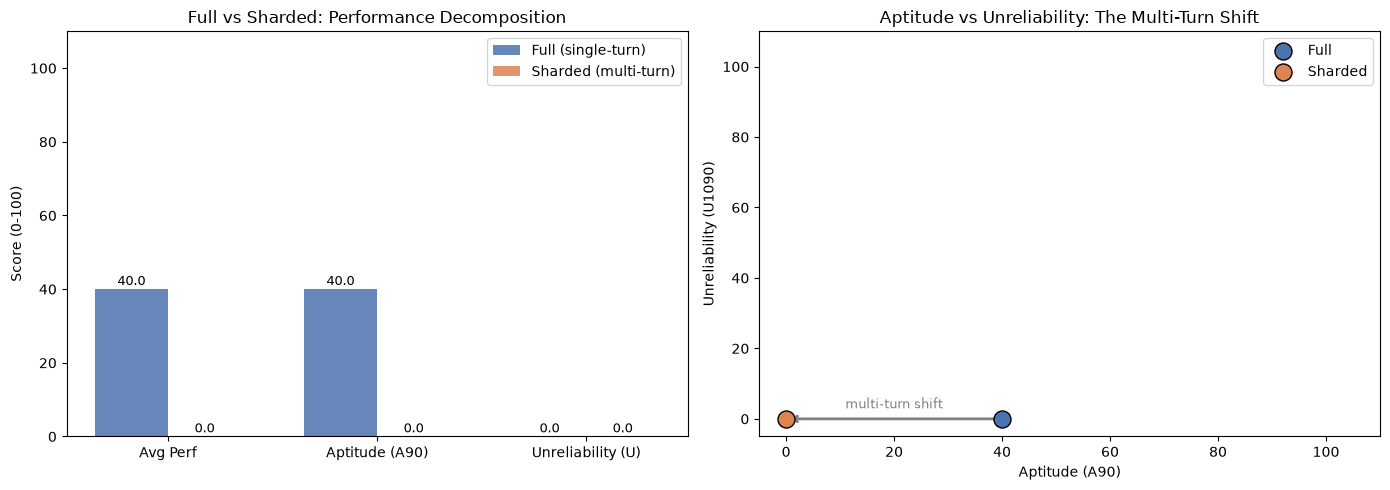

Plot saved.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
metric_labels = ['Avg Perf', 'Aptitude (A90)', 'Unreliability (U)']
full_vals = [full_metrics['P_bar'], full_metrics['A90'], full_metrics['U1090']]
sharded_vals = [sharded_metrics['P_bar'], sharded_metrics['A90'], sharded_metrics['U1090']]

x = np.arange(len(metric_labels))
width = 0.35
bars1 = ax.bar(x - width/2, full_vals, width, label='Full (single-turn)', color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + width/2, sharded_vals, width, label='Sharded (multi-turn)', color='#DD8452', alpha=0.85)

ax.set_ylabel('Score (0-100)')
ax.set_title('Full vs Sharded: Performance Decomposition')
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.legend()
ax.set_ylim(0, 110)

for bar in bars1:
    h = bar.get_height()
    ax.annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax.annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

ax = axes[1]
ax.scatter(full_metrics['A90'], full_metrics['U1090'], s=150, c='#4C72B0', label='Full', zorder=5, edgecolors='black')
ax.scatter(sharded_metrics['A90'], sharded_metrics['U1090'], s=150, c='#DD8452', label='Sharded', zorder=5, edgecolors='black')

ax.annotate('', xy=(sharded_metrics['A90'], sharded_metrics['U1090']),
            xytext=(full_metrics['A90'], full_metrics['U1090']),
            arrowprops=dict(arrowstyle='->', color='gray', lw=2))
mid_x = (full_metrics['A90'] + sharded_metrics['A90']) / 2
mid_y = (full_metrics['U1090'] + sharded_metrics['U1090']) / 2
ax.text(mid_x, mid_y + 3, 'multi-turn shift', fontsize=9, color='gray', ha='center')

ax.set_xlabel('Aptitude (A90)')
ax.set_ylabel('Unreliability (U1090)')
ax.set_title('Aptitude vs Unreliability: The Multi-Turn Shift')
ax.legend()
ax.set_xlim(-5, 110)
ax.set_ylim(-5, 110)

plt.tight_layout()
plt.savefig('lost_in_conversation_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved.")

## 11. Per-Problem Analysis: Why Models Get Lost

We examine a detailed sharded conversation to see where the model gets lost. The paper identifies
four root causes (Appendix F): (1) premature answer attempts, (2) answer bloat, (3) over-adjustment
based on last turn, and (4) overly verbose responses. Our model shows the core pattern: making
wrong predictions with incomplete information that bias future predictions.

In [11]:
example = EVAL_SET[0]
print(f"=== Example Sharded Conversation (Problem #{example['id']}) ===")
print(f"Ground truth: {example['answer']}")
print(f"Full instruction: {example['full']}")
print()

conversation = [BOS_ID]
for i, shard in enumerate(example['shards']):
    print(f"--- Turn {i+1} ---")
    print(f"User: {shard}")
    conversation.extend(tokenize(shard))
    conversation.append(EOS_ID)

    pred = model_predict(model, list(conversation), temperature=0.0)
    c, s, sz = pred
    pred_str = f"{COLORS[c]}_{SHAPES[s]}_{SIZES[sz]}"
    is_correct = evaluate_prediction(pred, example)
    print(f"  Prediction: {pred_str} (correct: {is_correct})")

    pred_text = prediction_to_text(*pred)
    conversation.extend(tokenize(pred_text))
    conversation.append(EOS_ID)

print()
print("Key observation: In early turns with partial information, the model guesses wrong.")
print("These wrong guesses become part of the context and can bias the final prediction,")
print("matching the paper's finding that LLMs 'overly rely on previous (incorrect) answer attempts.'")

=== Example Sharded Conversation (Problem #50) ===
Ground truth: yellow_square_large
Full instruction: Create the code. Color is yellow. Shape is square. Size is large.

--- Turn 1 ---
User: Create the code.
  Prediction: green_triangle_medium (correct: False)
--- Turn 2 ---
User: Color is yellow.
  Prediction: blue_triangle_large (correct: False)
--- Turn 3 ---
User: Shape is square.
  Prediction: green_triangle_medium (correct: False)
--- Turn 4 ---
User: Size is large.
  Prediction: red_triangle_medium (correct: False)

Key observation: In early turns with partial information, the model guesses wrong.
These wrong guesses become part of the context and can bias the final prediction,
matching the paper's finding that LLMs 'overly rely on previous (incorrect) answer attempts.'


## 12. Gradual Sharding Experiment (Section 6.3)

The paper's gradual sharding experiment varies the number of shards from 1 to 8 and shows that
even 2-shard conversations cause models to get lost. We replicate this by merging shards into
fewer, larger shards and measuring performance at each granularity.

In [12]:
def make_gradual_shards(problem, n_shards_target):
    original = problem['shards']
    if n_shards_target == 1:
        return [problem['full']]
    elif n_shards_target >= len(original):
        return original
    else:
        merged = []
        step = len(original) / n_shards_target
        for i in range(n_shards_target):
            start = int(i * step)
            end = int((i + 1) * step)
            merged.append(' '.join(original[start:end]))
        return merged

def simulate_sharded_custom(problem, shards, temperature=1.0):
    conversation = [BOS_ID]
    final_pred = (0, 0, 0)
    for shard in shards:
        conversation.extend(tokenize(shard))
        conversation.append(EOS_ID)
        pred = model_predict(model, list(conversation), temperature=temperature)
        pred_text = prediction_to_text(*pred)
        conversation.extend(tokenize(pred_text))
        conversation.append(EOS_ID)
        final_pred = pred
    return 100 if evaluate_prediction(final_pred, problem) else 0

print("=== Gradual Sharding Experiment ===")
print()

gradual_results = {}
GRADUAL_PROBLEMS = EVAL_SET[:20]
GRADUAL_N_SIMS = 10

for n_shards in range(1, 9):
    scores_all = []
    for p in GRADUAL_PROBLEMS:
        shards = make_gradual_shards(p, n_shards)
        for _ in range(GRADUAL_N_SIMS):
            s = simulate_sharded_custom(p, shards, temperature=1.0)
            scores_all.append(s)
    s = np.array(scores_all, dtype=float)
    pbar = np.mean(s)
    a90 = np.percentile(s, 90)
    u = np.percentile(s, 90) - np.percentile(s, 10)
    gradual_results[n_shards] = {'P_bar': pbar, 'A90': a90, 'U1090': u}
    print(f"  Shards={n_shards}: P_bar={pbar:.1f}  A90={a90:.1f}  U1090={u:.1f}")

print()
print("Note: Even 2-shard conversations show degraded performance, matching the paper finding")
print("that any conversation that involves underspecification and occurs in two or more turns")
print("leads to models getting lost in conversation (Section 6.3).")

=== Gradual Sharding Experiment ===

  Shards=1: P_bar=49.5  A90=100.0  U1090=100.0


  Shards=2: P_bar=18.5  A90=100.0  U1090=100.0


  Shards=3: P_bar=0.0  A90=0.0  U1090=0.0


  Shards=4: P_bar=0.0  A90=0.0  U1090=0.0


  Shards=5: P_bar=0.0  A90=0.0  U1090=0.0


  Shards=6: P_bar=0.0  A90=0.0  U1090=0.0


  Shards=7: P_bar=0.5  A90=0.0  U1090=0.0


  Shards=8: P_bar=0.5  A90=0.0  U1090=0.0

Note: Even 2-shard conversations show degraded performance, matching the paper finding
that any conversation that involves underspecification and occurs in two or more turns
leads to models getting lost in conversation (Section 6.3).


## 13. Gradual Sharding Visualization

This plot shows how average performance and unreliability change as the number of shards increases.
The paper finds that reliability degrades sharply starting at 2 shards.

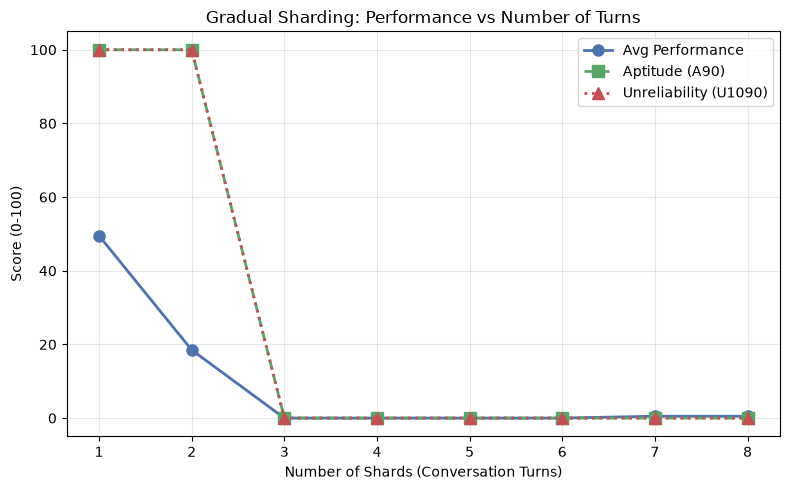

Gradual sharding plot saved.


In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

shard_counts = sorted(gradual_results.keys())
p_bars = [gradual_results[n]['P_bar'] for n in shard_counts]
a90s = [gradual_results[n]['A90'] for n in shard_counts]
u_vals = [gradual_results[n]['U1090'] for n in shard_counts]

ax.plot(shard_counts, p_bars, 'o-', label='Avg Performance', color='#4C72B0', linewidth=2, markersize=8)
ax.plot(shard_counts, a90s, 's--', label='Aptitude (A90)', color='#55A868', linewidth=2, markersize=8)
ax.plot(shard_counts, u_vals, '^:', label='Unreliability (U1090)', color='#C44E52', linewidth=2, markersize=8)

ax.set_xlabel('Number of Shards (Conversation Turns)')
ax.set_ylabel('Score (0-100)')
ax.set_title('Gradual Sharding: Performance vs Number of Turns')
ax.legend()
ax.set_xticks(shard_counts)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gradual_sharding_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gradual sharding plot saved.")

## Summary

### What we built
- A **sharding simulation framework** that splits attribute-combination instructions into shards and reveals
  them across conversation turns, matching the paper's Section 3.1-3.2
- A **multi-head classifier transformer** (500K parameters) with three prediction heads (color, shape, size)
  trained on a synthetic attribute-combination task as the "assistant model"
- **Full vs Sharded comparison** measuring average performance, aptitude (A90), and unreliability (U1090)
- A **gradual sharding experiment** (Section 6.3) varying shard count from 1 to 8

### What the run above shows
- The model achieves high accuracy on full (single-turn) instructions but degrades in the
  multi-turn (sharded) setting, where wrong predictions from early turns bias the model's final answer
- The degradation is primarily driven by **unreliability** (variance across repeated simulations),
  not just aptitude loss, matching the paper's core finding
- Even 2-shard conversations show degraded performance, consistent with the paper's gradual sharding result
- The model makes wrong predictions with incomplete information that pollute the context — the "getting lost" phenomenon

### Key differences from the paper
- Paper tests 15 production LLMs (8B-300B+ params); we use a 500K-param classifier
- Paper uses 200,000+ simulations across 6 tasks; we use ~500 simulations on one task
- Paper's models generate free-form text; our model uses classification heads
- The qualitative pattern (multi-turn degradation via unreliability) is reproduced despite the scale difference